# 04 — From effects to pass-through: US import exposure of each treated series

Next step 4a in `CONTRIBUTING.md` (decision D21). D20 found no detectable effect, but an effect alone cannot be compared with the Bank of Canada pass-through rates [R1–R3]: it depends on how much of each CPI series is made of tariffed US goods.

- **Exposure** `s_i` = US imports of the tariffed HS6 subheadings mapped to the series (UN Comtrade [S12], year before the tariff, converted with the annual USD/CAD rate) ÷ household spending on the series (CPI basket weight [S13] × HFCE on food and non-alcoholic beverages [S14], same year).
- **Expected effect at 100% pass-through** = tariff rate × `s_i`.
- **Pass-through** = observed effect ÷ expected effect, estimated jointly with a continuous-treatment DiD (dose = 100 × tariff × `s_i`, 0 for controls) [M3, M5].

In [1]:
import sys
from pathlib import Path
root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(root / "src"), str(root / "src" / "causal")]
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import exposure as E, synth as S
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 60)

roles = pd.read_csv(root / "data/processed/treatment_roles.csv")
cat = pd.read_csv(root / "data/processed/cpi_food_catalog.csv")
parent = dict(zip(cat["product"], cat["parent"]))
sc = pd.read_csv(root / "data/processed/sc_results.csv")
x = E.exposure(roles)
x.to_csv(root / "data/processed/exposure.csv", index=False)
print("Annual USD/CAD:", E.usdcad_annual().loc[[2017, 2024]].round(4).to_dict())

Annual USD/CAD: {2017: 1.2986, 2024: 1.3698}


## 1. Exposure of each treated series

In [2]:
x[["event_id", "series", "weight_class", "spending_musd_cad", "us_imports_mcad", "us_share_of_imports",
   "exposure_s", "expected_effect_full_pt", "hs6_broader"]].round(3)

,event_id,series,weight_class,spending_musd_cad,us_imports_mcad,us_share_of_imports,exposure_s,expected_effect_full_pt,hs6_broader
0,CA2018,Other dairy products,Other dairy products,3468.894,3.516,0.985,0.001,0.010,
1,CA2018,Other bakery products,Other bakery products,3468.894,1242.594,0.858,0.358,3.582,"pizza, quiche, pastries and cakes only (1905.90.51)"
2,CA2018,Fruit juices,Fruit juices,1638.089,165.339,0.671,0.101,1.009,
3,CA2018,"Jam, jelly and other preserves (2013=100)",Other preserved fruit and fruit preparations,1252.656,74.539,0.661,0.060,0.595,strawberry jam only (2007.99.10)
4,CA2018,Confectionery,Confectionery,3950.684,520.366,0.605,0.132,1.317,
5,CA2018,Roasted or ground coffee (2013=100),Coffee,2794.387,521.100,0.748,0.186,1.865,
6,CA2018,Fermented or pickled vegetables (2013=100),"Condiments, spices and vinegars",3565.252,68.856,0.793,0.019,0.193,
7,CA2018,"Sauces, condiments and dips (2013=100)","Condiments, spices and vinegars",3565.252,818.462,0.852,0.230,2.296,
8,CA2018,Soup,Soup,963.582,204.118,0.772,0.212,2.118,
9,CA2018,Non-alcoholic beverages,Non-alcoholic beverages,4528.833,253.347,0.644,0.056,0.559,


In [3]:
x.groupby("event_id").agg(n=("series", "size"), median_s=("exposure_s", "median"), max_s=("exposure_s", "max"),
                          mean_expected_full_pt=("expected_effect_full_pt", "mean")).round(3)

,n,median_s,max_s,mean_expected_full_pt
event_id,,,,
CA2018,10,0.116,0.358,1.355
CA2025,22,0.092,0.329,3.025


## 2. Pass-through by series (synthetic-control effect ÷ expected effect at full pass-through)

Very noisy when the expected effect is small: a 1-point gap on a 0.2-point expected effect reads as 500%.

In [4]:
m = x.merge(sc[sc.group == "treated"][["event_id", "series", "effect_during", "p_value"]], on=["event_id", "series"])
m["pass_through_series"] = m.effect_during / m.expected_effect_full_pt
m[["event_id", "series", "expected_effect_full_pt", "effect_during", "p_value", "pass_through_series"]].round(2)

,event_id,series,expected_effect_full_pt,effect_during,p_value,pass_through_series
0,CA2018,Other dairy products,0.01,1.74,0.13,171.31
1,CA2018,Other bakery products,3.58,-2.07,0.28,-0.58
2,CA2018,Fruit juices,1.01,-3.13,0.40,-3.11
3,CA2018,"Jam, jelly and other preserves (2013=100)",0.60,-2.69,0.11,-4.52
4,CA2018,Confectionery,1.32,-1.80,0.32,-1.37
5,CA2018,Roasted or ground coffee (2013=100),1.86,-2.11,0.51,-1.13
6,CA2018,Fermented or pickled vegetables (2013=100),0.19,-4.01,0.28,-20.76
7,CA2018,"Sauces, condiments and dips (2013=100)",2.30,-0.89,0.62,-0.39
8,CA2018,Soup,2.12,-1.75,0.15,-0.83
9,CA2018,Non-alcoholic beverages,0.56,-1.17,0.49,-2.09


## 3. Pooled pass-through: continuous-treatment DiD (main result)

In [5]:
wide = S.cpi_wide()
rows = []
for ev, ep in S.EPISODES.items():
    u = roles[(roles.event_id == ev) & roles.usable]
    tr = u[u.role == "treated"]["product"].tolist()
    don = S.finest(u[u.role == "control"]["product"].tolist(), parent)
    Y = S.outcome(wide, ep, tr + don, "main").dropna(axis=1)
    w = ep.windows(wide.index.max())
    xe = x[x.event_id == ev]
    variants = {"all treated series": xe,
                "exact HS6 only (no broader codes)": xe[xe.hs6_broader.fillna("") == ""],
                "own basket weight only": xe[~xe.weight_from_proxy]}
    if ev == "CA2025":
        variants["without coffee and confectionery"] = xe[~xe.series.isin(["Roasted or ground coffee (2013=100)", "Confectionery"])]
    for k, v in variants.items():
        rows.append({"event_id": ev, "variant": k, **E.intensity_did(Y, v, don, ep.first_month, ep.last_month, w["pre"][0])})
pt = pd.DataFrame(rows)
pt.to_csv(root / "data/processed/pass_through.csv", index=False)
pt.round(3)

,event_id,variant,pass_through,lo,hi,p,n_treated,n_donors
0,CA2018,all treated series,-0.957,-2.450,0.536,0.209,10,52
1,CA2018,exact HS6 only (no broader codes),-1.780,-3.550,-0.011,0.049,8,52
2,CA2018,own basket weight only,-0.160,-1.047,0.728,0.724,6,52
3,CA2025,all treated series,0.833,-0.112,1.779,0.084,22,22
4,CA2025,exact HS6 only (no broader codes),1.115,-0.095,2.325,0.071,19,22
5,CA2025,own basket weight only,0.270,-0.192,0.732,0.252,17,22
6,CA2025,without coffee and confectionery,0.347,-0.121,0.814,0.146,20,22


## 4. Expected vs observed effect

Each dot is a treated series. Lines show what full, 70% (R3, 2018 food) and 25% (R1/R2, 2025) pass-through would imply.

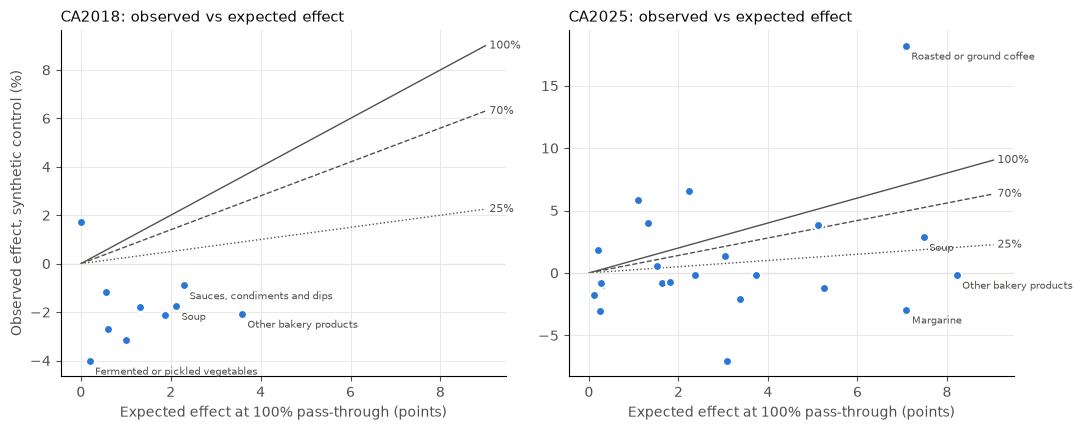

In [6]:
BLUE, INK, MUTED, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#e6e5e0"
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, ev in zip(axes, ["CA2018", "CA2025"]):
    d = m[m.event_id == ev]
    lim = max(9, d.expected_effect_full_pt.max() * 1.1)
    xs = np.linspace(0, lim, 50)
    for k, style in [(1.0, "-"), (0.7, "--"), (0.25, ":")]:
        ax.plot(xs, k * xs, color=MUTED, lw=1, ls=style)
        ax.text(lim, k * lim, f" {int(k * 100)}%", color=MUTED, va="center", fontsize=8)
    ax.axhline(0, color=GRID, lw=1)
    ax.scatter(d.expected_effect_full_pt, d.effect_during, color=BLUE, s=42, edgecolor="white", linewidth=1.5, zorder=3)
    lab = pd.concat([d.nlargest(3, "expected_effect_full_pt"), d.loc[[d.effect_during.abs().idxmax()]]]).drop_duplicates("series")
    for _, r in lab.iterrows():
        ax.annotate(r.series.replace(" (2013=100)", ""), (r.expected_effect_full_pt, r.effect_during),
                    textcoords="offset points", xytext=(4, -10), fontsize=7, color=MUTED)
    ax.set_title(f"{ev}: observed vs expected effect", color=INK, fontsize=11, loc="left")
    ax.set_xlabel("Expected effect at 100% pass-through (points)", color=MUTED)
    ax.tick_params(colors=MUTED)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(color=GRID, lw=0.6)
axes[0].set_ylabel("Observed effect, synthetic control (%)", color=MUTED)
plt.tight_layout(); plt.show()

## 5. Findings

Written up in D21 (decision log).